In [29]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt

polyline = pygplates.PolylineOnSphere([(-60,40),(-50,40),(-40,35), (-20,40)])

#print polyline.get_arc_length()


total_weight = 0.
net_torque = 0.

for i,segment in enumerate(polyline.get_segments()):
    
    
    normal = segment.get_great_circle_normal()
    
    segment_position_vector = segment.get_arc_point(0.5).to_xyz()
    
    segment_weight = segment.get_arc_length()
    
    total_weight += segment_weight
    
    segment_torque = pygplates.Vector3D.cross(normal,segment_position_vector) * segment_weight
    
    if i==0:
        total_torque = segment_torque
        
    else:
        total_torque = total_torque + segment_torque
        
    print segment_torque.get_magnitude(), total_torque.get_magnitude()
    



0.174532925199 0.174532925199
0.185012193521 0.351943021019
0.356988682564 0.686332405046


0.000304617419787 (35.0, 40.0) 0.174532925199
0.000614256449619 (39.43198847093019, 25.76135215596254) 0.185012193521
0.00119787602312 (50.019505693616495, 40.03384971631634) 0.356988682564


[-180, 180, -90, 90]

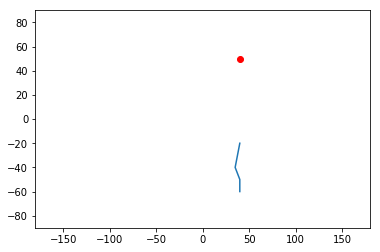

In [30]:
# cross product of normal and position of mid point

for i,segment in enumerate(polyline.get_segments()):
    
    
    normal = segment.get_great_circle_normal()
    
    segment_position_vector = segment.get_arc_point(0.5).to_xyz()
    
    segment_weight = segment.get_arc_length()
        
    stage_pole_position = pygplates.Vector3D.cross(normal,segment_position_vector)
    rotation_rate_vector = pygplates.Vector3D(stage_pole_position.to_xyz()) * np.radians(0.1)
    
    v = pygplates.Vector3D.cross(rotation_rate_vector, segment_position_vector)
    
    if i==0:
        weighting_factor = 0
        net_torque = pygplates.Vector3D(0, 0, 0)

    net_torque = net_torque + pygplates.Vector3D.cross(segment_position_vector, v) * segment_weight
    
    print net_torque.get_magnitude(), pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon(), segment_weight
    
plt.plot(polyline.to_lat_lon_array()[:,1],polyline.to_lat_lon_array()[:,0])
plt.plot(pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[1],
         pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[0],'ro')
plt.axis([-180,180,-90,90])
